### Purpose:
A code to solve Equation:
D = Ke / (0.09 * b**2 *abs(ln (2e7*D**0.5)))

### with Parameters
Ke = 4.8 e-8
b = 3.5 e-8

Abstract 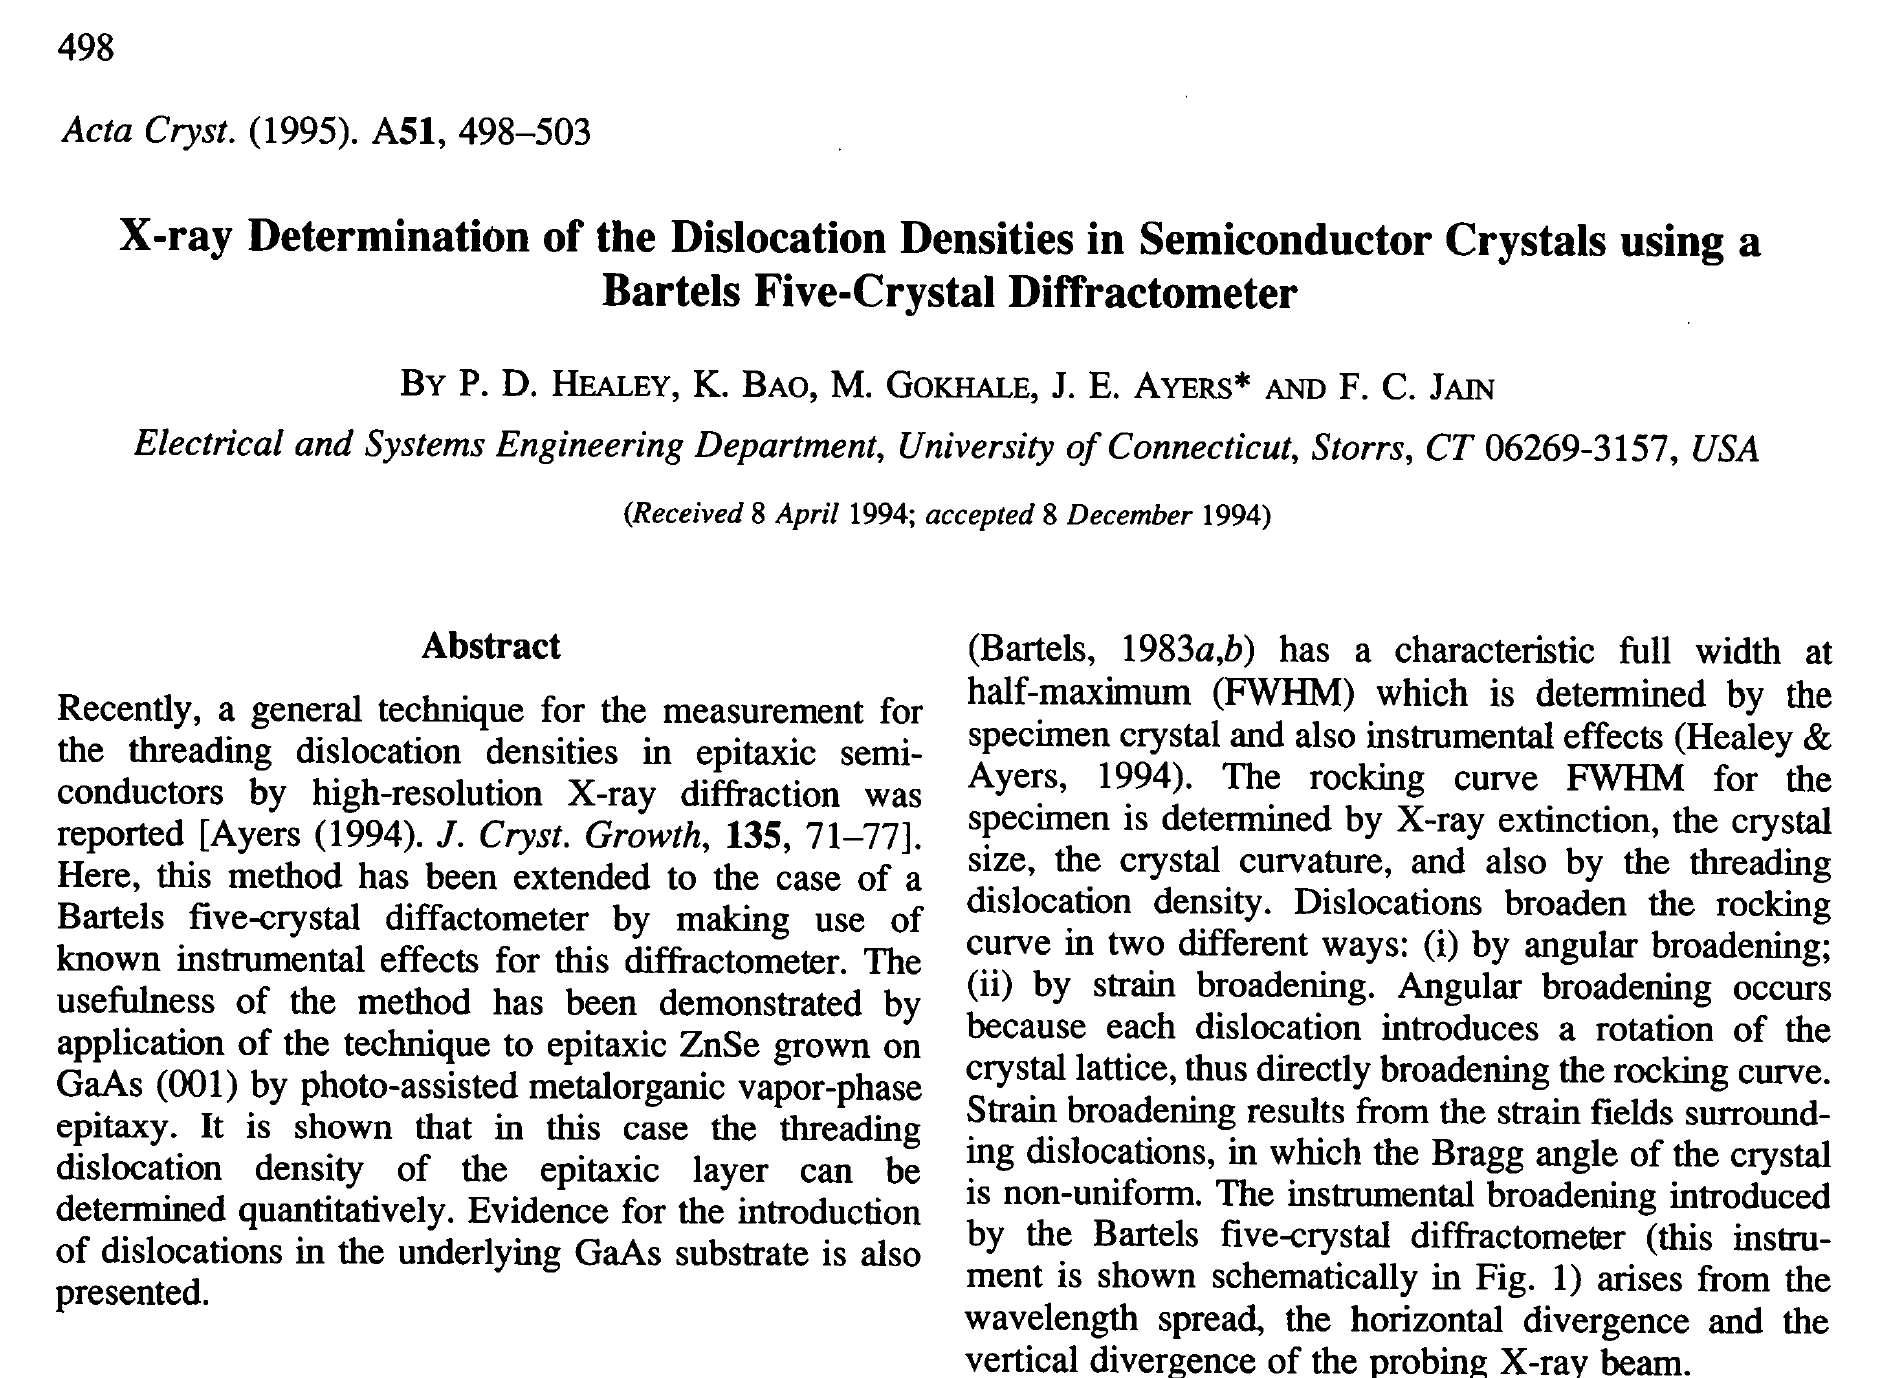

Equation 18 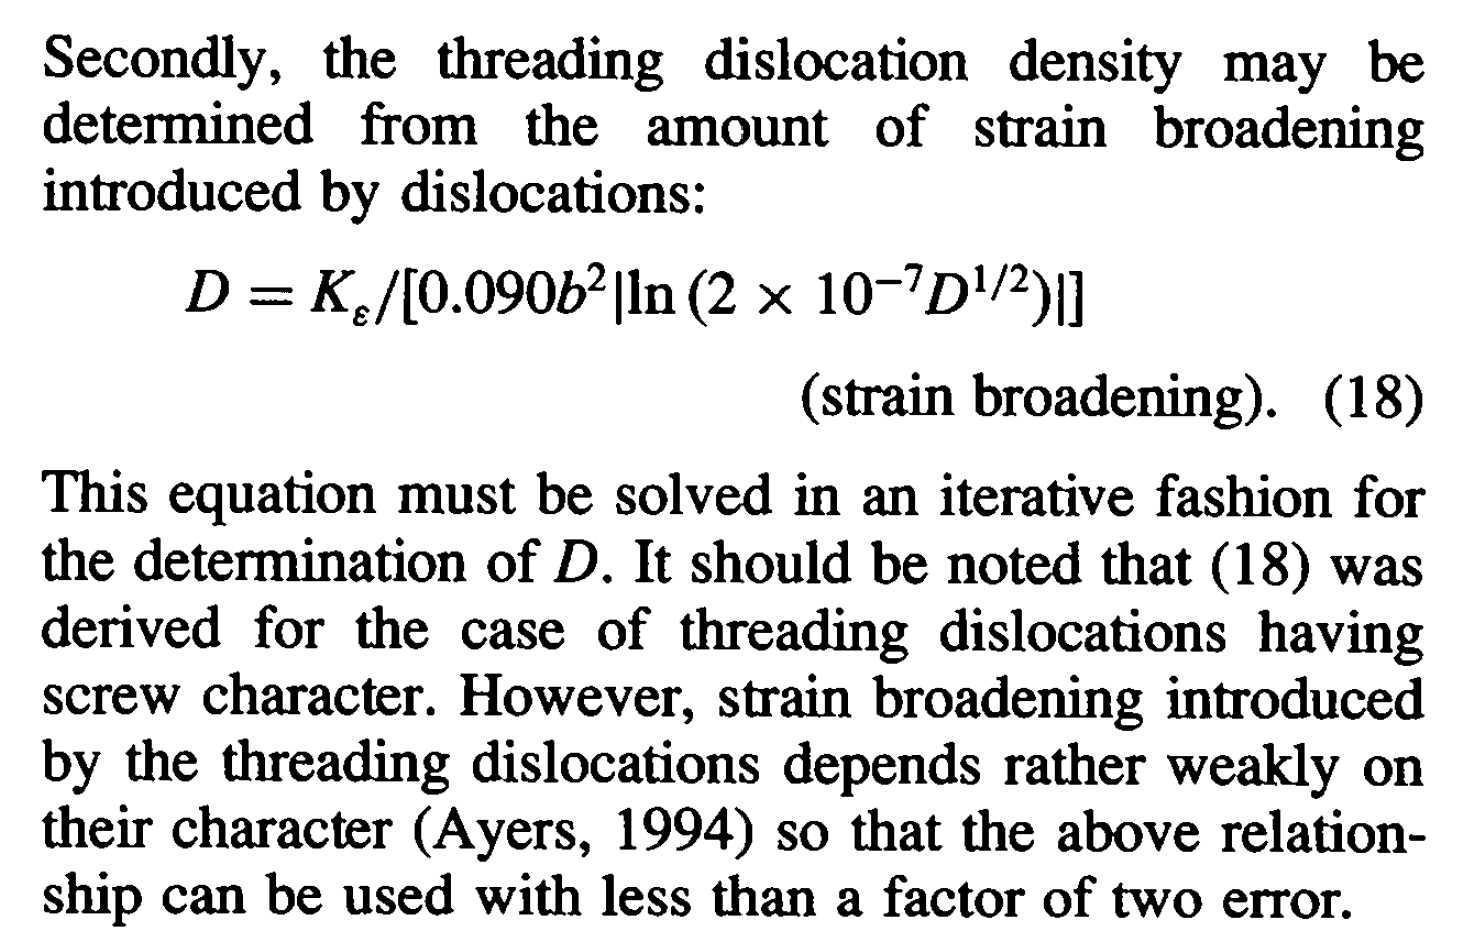

In [4]:

import numpy as np
from scipy.optimize import fsolve

# Given parameters
Ke = 4.8e-8
b = 3.5e-8

# Define the function to find the root of: F(D) = 0
def equation(D):
    if D <= 0:
        return 1e10  # Prevent invalid values for log/sqrt
    
    # Denominator expression
    denominator = 0.09 * (b**2) * np.abs(np.log(2e7 * np.sqrt(D)))
    
    if denominator == 0:
        return 1e10
        
    return D - (Ke / denominator)

# Provide an initial guess for D
initial_guess = 1.0e7

# Solve numerically
solution = fsolve(equation, initial_guess)
D_value = solution[0]

print(f"Numerical solution for D: {D_value:.6e}")

# Verification
verification_rhs = Ke / (0.09 * (b**2) * np.abs(np.log(2e7 * np.sqrt(D_value))))
print(f"Left-hand side (D): {D_value}")
print(f"Right-hand side:     {verification_rhs}")

Numerical solution for D: 1.731470e+07
Left-hand side (D): 17314695.945505053
Right-hand side:     17314695.945505053


Numerical solution for D: 1.731470e+07
Left-hand side (D): 17314695.945505057
Right-hand side:     17314695.945505053


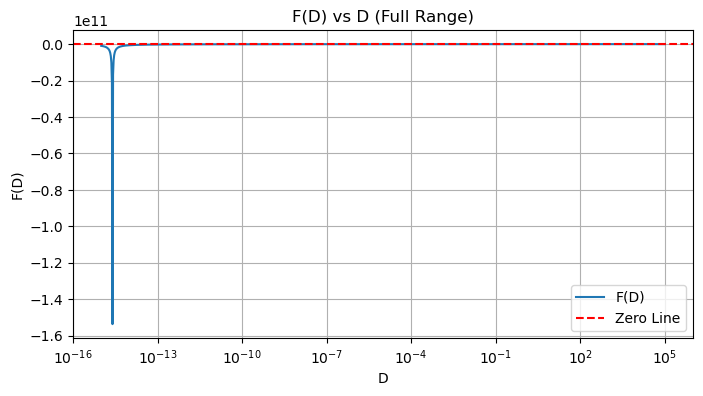

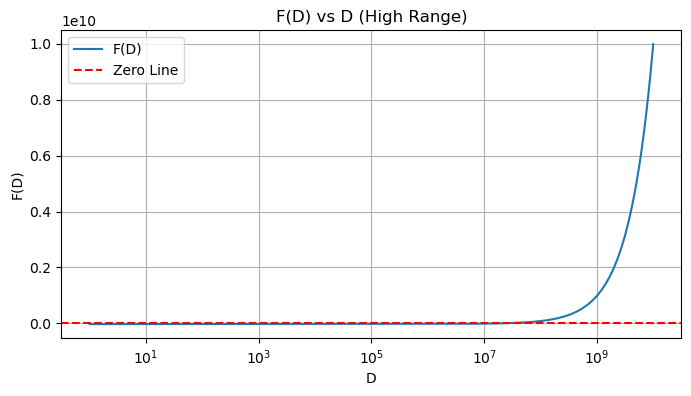

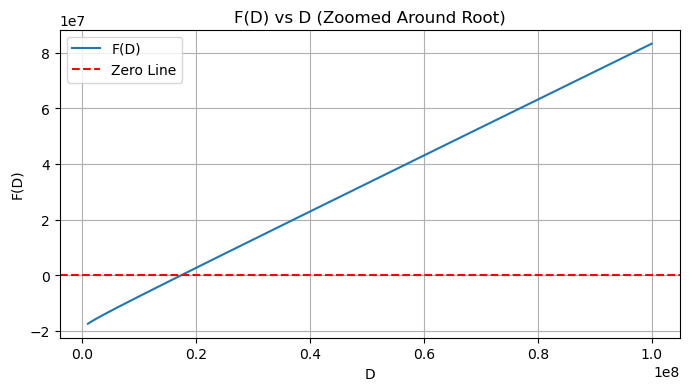

In [5]:
import numpy as np
from scipy.optimize import fsolve
import matplotlib.pyplot as plt

# Given parameters
Ke = 4.8e-8
b = 3.5e-8

# Define the function to find the root of: F(D) = 0
def equation(D):
    if D <= 0:
        return 1e10  # Prevent invalid values for log/sqrt
    
    # Denominator expression
    denominator = 0.09 * (b**2) * np.abs(np.log(2e7 * np.sqrt(D)))
    
    if denominator == 0:
        return 1e10
        
    return D - (Ke / denominator)

# 1. Numerical Solver
initial_guess = 1.0
solution = fsolve(equation, initial_guess)
D_value = solution[0]

print(f"Numerical solution for D: {D_value:.6e}")

# Verification
verification_rhs = Ke / (0.09 * (b**2) * np.abs(np.log(2e7 * np.sqrt(D_value))))
print(f"Left-hand side (D): {D_value}")
print(f"Right-hand side:     {verification_rhs}")

# 2. Plotting F(D) vs D across different ranges

# --- Plot 1: Full Range ---
Ds_full = np.logspace(-15, 5, 1000)
vals_full = [equation(d) for d in Ds_full]

plt.figure(figsize=(8, 4))
plt.plot(Ds_full, vals_full, label="F(D)")
plt.axhline(0, color='r', linestyle='--', label="Zero Line")
plt.xscale('log')
plt.grid(True)
plt.title("F(D) vs D (Full Range)")
plt.xlabel("D")
plt.ylabel("F(D)")
plt.legend()
plt.savefig("equation_root_full.png")
# plt.close()
plt.show()

# --- Plot 2: High Range ---
Ds_high = np.logspace(0, 10, 1000)
vals_high = [equation(d) for d in Ds_high]

plt.figure(figsize=(8, 4))
plt.plot(Ds_high, vals_high, label="F(D)")
plt.axhline(0, color='r', linestyle='--', label="Zero Line")
plt.xscale('log')
plt.grid(True)
plt.title("F(D) vs D (High Range)")
plt.xlabel("D")
plt.ylabel("F(D)")
plt.legend()
plt.savefig("equation_root_high.png")
# plt.close()
plt.show()

# --- Plot 3: Zoomed Around the Root ---
Ds_zoom = np.linspace(1e6, 1e8, 1000)
vals_zoom = [equation(d) for d in Ds_zoom]

plt.figure(figsize=(8, 4))
plt.plot(Ds_zoom, vals_zoom, label="F(D)")
plt.axhline(0, color='r', linestyle='--', label="Zero Line")
plt.grid(True)
plt.title("F(D) vs D (Zoomed Around Root)")
plt.xlabel("D")
plt.ylabel("F(D)")
plt.legend()
plt.savefig("equation_root_zoom.png")
# plt.close()
plt.show()